In [6]:
from model_layer import Model, Layer

model = Model(
    [Layer([1, 2, 3], [1, 2, 3], Layer.sigmoid),
     Layer([[1,2],[3,4],[5,6]], [0, 1], Layer.ReLU)],
    )
print(model.forward_propagate(1))

[ 8.81447533 12.67481358]


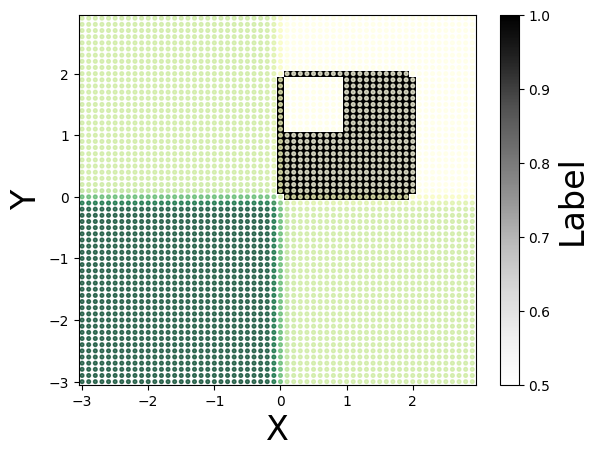

In [84]:
import matplotlib.pyplot as plt
import numpy as np


def S(x):
    return Layer.sigmoid(x)

plot_range = 3
x = np.arange(-plot_range, plot_range, 0.1) #x軸の描画範囲の生成。-1.25から1.25まで0.01刻み。
y = np.arange(-plot_range, plot_range, 0.1) #y軸の描画範囲の生成。1.25から1.25まで0.01刻み。
X, Y = np.meshgrid(x, y)

def square(x,y, c_1 = (0,0), c_2 = (1,1), L = 100):
  return S(L*(S(L*(x-c_1[0]))+S(L*(y-c_1[1]))+S(L*(c_2[0]-x))+S(L*(c_2[1]-y))-3.5))


L_shape_model = Model(
    [Layer([[20, 0, 0, 0],[0, 20, 0, 0]], bias=[0, 0, 0, 0], activation=Layer.sigmoid),
     #Layer([[1,1,1,1],[1,1,1,1],[1,1,1,1],[1,1,1,1]], bias=[1, 1, 1, 1], activation=Layer.sigmoid),
     Layer([[1],[1],[1],[1]], bias=[1], activation=Layer.sigmoid),]
    )

L = 50.0

Z = S(L*(S(L*square(X, Y, (0,0),(2,2), L)) + S(L*(1-square(X, Y, (0,1),(1,2), L))) - 1.5))
Z_1 = [L_shape_model.forward_propagate((x[i],y[j])) for i in range(len(x)) for j in range(len(y))]




plt.xlabel('X', fontsize=24)
plt.ylabel('Y', fontsize=24)
plt.pcolormesh(X,Y,Z, cmap='Greys') #カラー等高線図
pp=plt.colorbar (orientation="vertical") # カラーバーの表示
pp.set_label("Label",  fontsize=24)


plt.scatter(X, Y, c=Z_1, cmap='YlGn_r', alpha=0.7, s=7)
plt.show()